In [1]:
%pip install landingai pillow numpy matplotlib

  Using cached landingai-0.3.49-py3-none-any.whl.metadata (8.6 kB)
  Using cached aiohttp-3.14.5-cp310-cp310-win_amd64.whl.metadata (8.5 kB)
  Using cached imageio-2.38.0-py3-none-any.whl.metadata (9.7 kB)
  Using cached opencv_python-4.14.0.94-cp37-abi3-win_amd64.whl.metadata (20 kB)
  Using cached pydantic_settings-2.15.0-py3-none-any.whl.metadata (3.9 kB)
  Using cached requests_toolbelt-1.0.0-py2.py3-none-any.whl.metadata (14 kB)
  Using cached segmentation_mask_overlay-0.3.4-py3-none-any.whl.metadata (2.0 kB)
  Using cached aiosignal-1.4.0-py3-none-any.whl.metadata (3.7 kB)
  Using cached aiodns-4.0.4-py3-none-any.whl.metadata (9.0 kB)
INFO: pip is looking at multiple versions of opencv-python to determine which version is compatible with other requirements. This could take a while.
  Using cached opencv_python-4.13.0.92-cp37-abi3-win_amd64.whl.metadata (20 kB)
  Using cached opencv_python-4.13.0.90-cp37-abi3-win_amd64.whl.metadata (20 kB)
  Using cached opencv_python-4.12.0.88-cp

In [2]:
import os
import io
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from getpass import getpass
from tkinter import Tk, filedialog
from landingai.predict import Predictor

print("All libraries imported successfully.")

All libraries imported successfully.


In [3]:
API_KEY = getpass("Enter your LandingAI API Key: ")

ENDPOINT_ID = "fadcff2d-c799-4d53-9341-fb9a9f6a691a"

predictor = Predictor(
    endpoint_id=ENDPOINT_ID,
    api_key=API_KEY
)

print("LandingAI predictor initialized successfully.")

Enter your LandingAI API Key:  ········


LandingAI predictor initialized successfully.


In [18]:
root = Tk()
root.withdraw()
root.attributes("-topmost", True)

file_paths = filedialog.askopenfilenames(
    title="Select Medicine Bottle Images",
    filetypes=[
        ("Image files", "*.jpg *.jpeg *.png *.bmp")
    ]
)

root.destroy()

print("Total images selected:", len(file_paths))

Total images selected: 5


alendronate_jpeg.rf.e094ca68cec0da68f91f325f18da1449.jpg


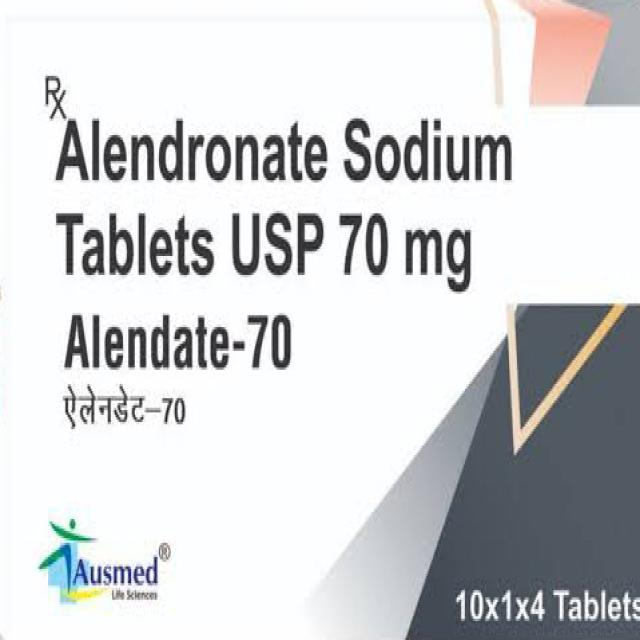

allopurinol_jpeg.rf.d5e2e2af98336e76a1261e77f3f30d53.jpg


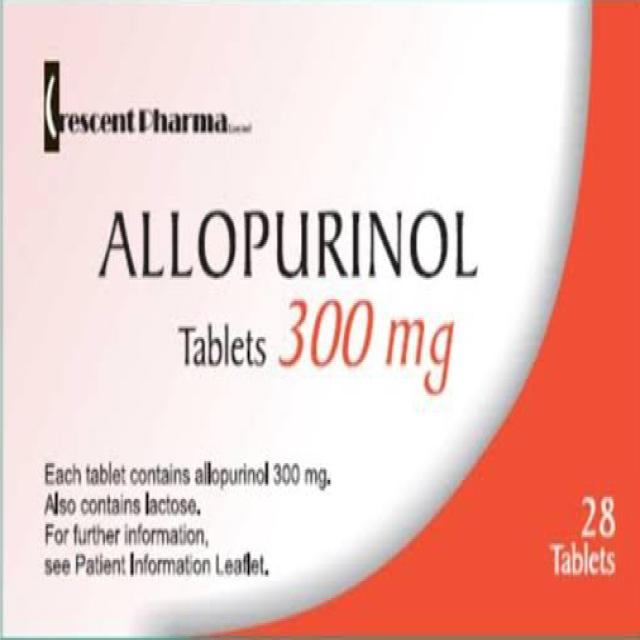

alprozlam_jpg.rf.f1ae0773f2edad3073724b10aa6fb55d.jpg


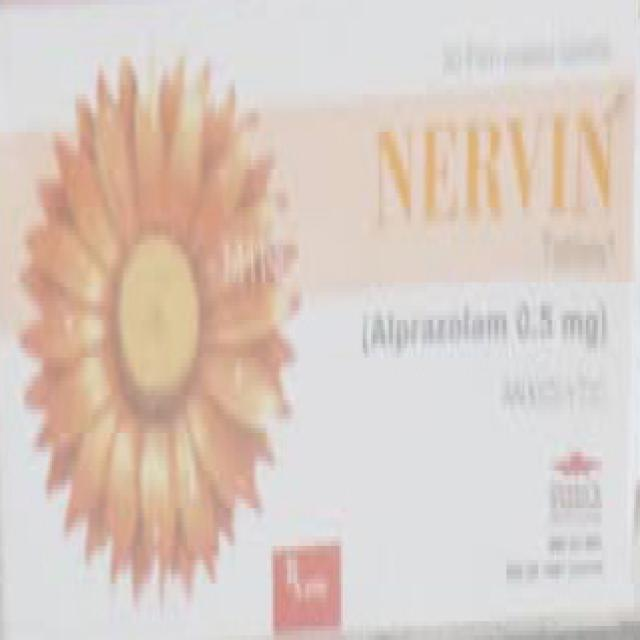

aripiprazole_jpeg.rf.8018e2564959b4bd0e6cdba8089f463e.jpg


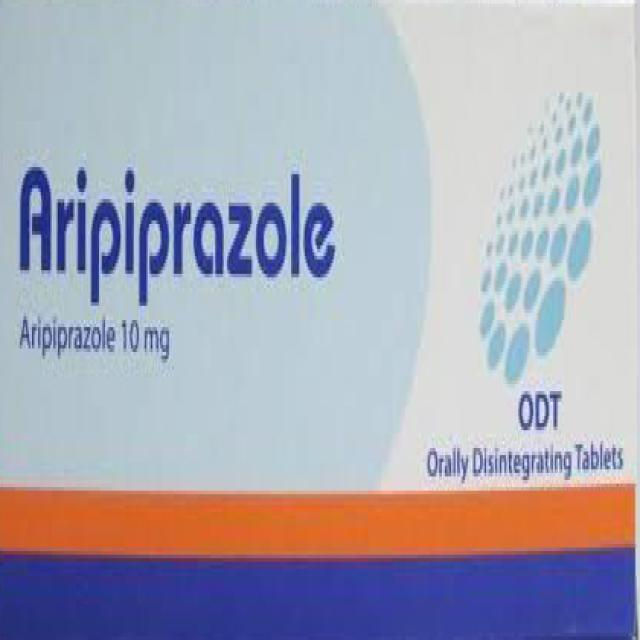

budesonide_jpeg.rf.c44d5caca23db70b7b8df67293a2aa7b.jpg


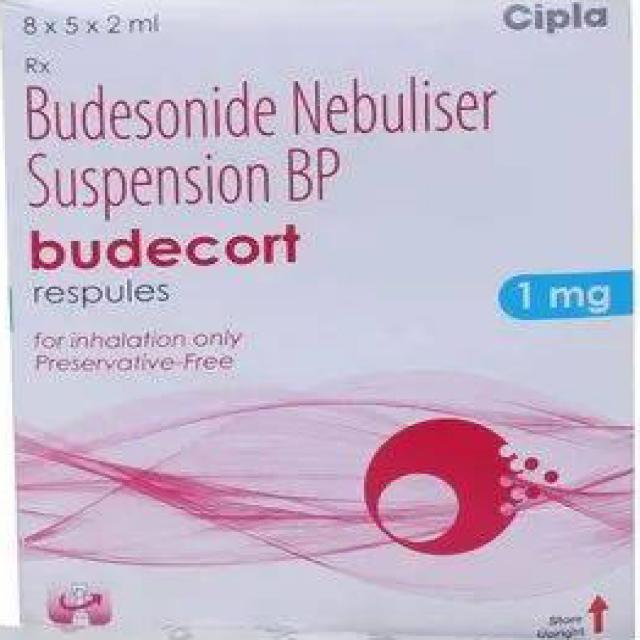

In [19]:
from IPython.display import display

for file_path in file_paths:
    print(os.path.basename(file_path))
    display(Image.open(file_path).convert("RGB"))

Medicine Bottle Cognitive Assistant

MEDICINE IMAGE 1: alendronate_jpeg.rf.e094ca68cec0da68f91f325f18da1449.jpg


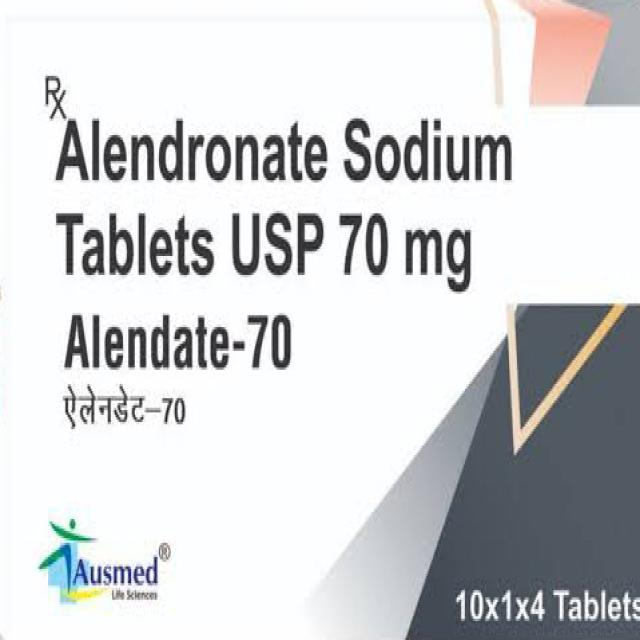


MODEL ANALYSIS
----------------------------------------
Prediction count: 1

Prediction 1:
Raw prediction: score=0.9493275284767151 label_name='Medicine' label_index=1 id='6b580781-caa9-43a0-a717-b57cec29524b' bboxes=(20, 78, 510, 329)
Detected label: Medicine
Class index: 1
Confidence: 0.9493275284767151

MEDICINE IMAGE 2: allopurinol_jpeg.rf.d5e2e2af98336e76a1261e77f3f30d53.jpg


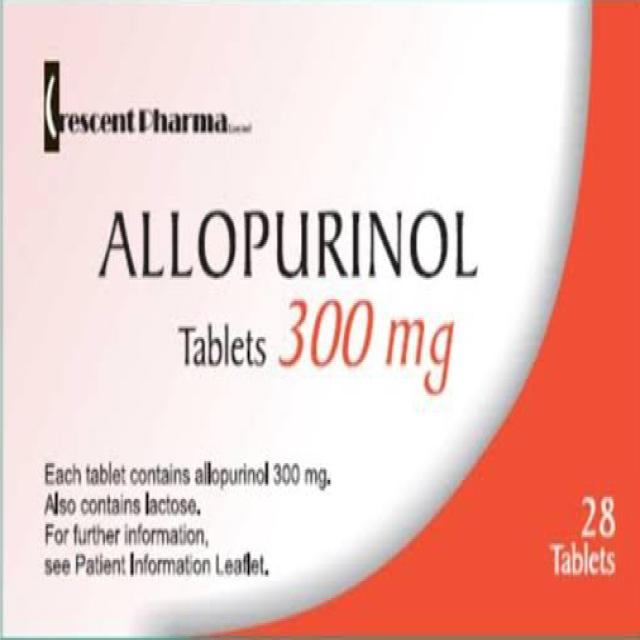


MODEL ANALYSIS
----------------------------------------
Prediction count: 1

Prediction 1:
Raw prediction: score=0.9668681025505066 label_name='Medicine' label_index=1 id='b92b6f7a-10fc-461b-bd3a-8c534383bc0b' bboxes=(71, 172, 489, 328)
Detected label: Medicine
Class index: 1
Confidence: 0.9668681025505066

MEDICINE IMAGE 3: alprozlam_jpg.rf.f1ae0773f2edad3073724b10aa6fb55d.jpg


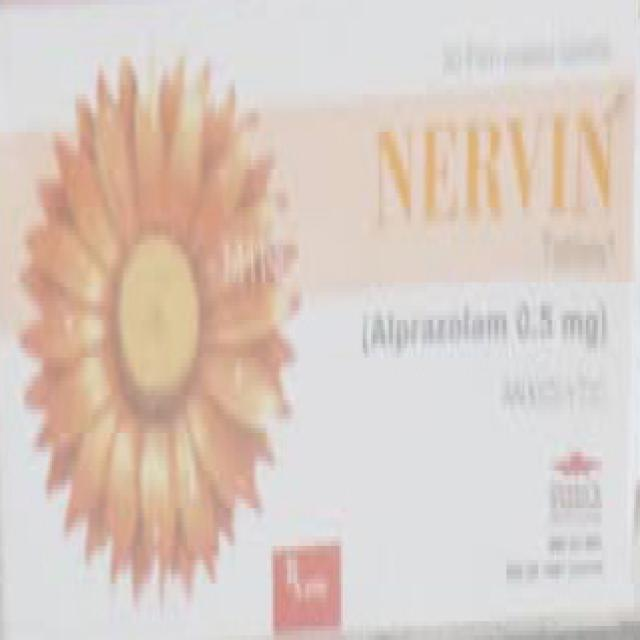


MODEL ANALYSIS
----------------------------------------
Prediction count: 1

Prediction 1:
Raw prediction: score=0.8993701934814453 label_name='Medicine' label_index=1 id='3c1f0274-e521-4caf-8bba-0db5ee52a835' bboxes=(352, 70, 627, 240)
Detected label: Medicine
Class index: 1
Confidence: 0.8993701934814453

MEDICINE IMAGE 4: aripiprazole_jpeg.rf.8018e2564959b4bd0e6cdba8089f463e.jpg


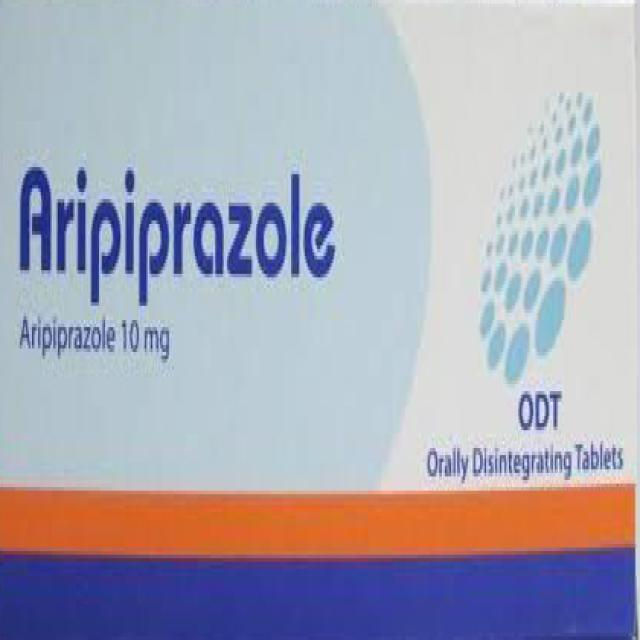


MODEL ANALYSIS
----------------------------------------
Prediction count: 1

Prediction 1:
Raw prediction: score=0.9827649593353271 label_name='Medicine' label_index=1 id='0d67964f-112b-44cd-bbf5-d6a2d7f6bd5c' bboxes=(3, 146, 342, 324)
Detected label: Medicine
Class index: 1
Confidence: 0.9827649593353271

MEDICINE IMAGE 5: budesonide_jpeg.rf.c44d5caca23db70b7b8df67293a2aa7b.jpg


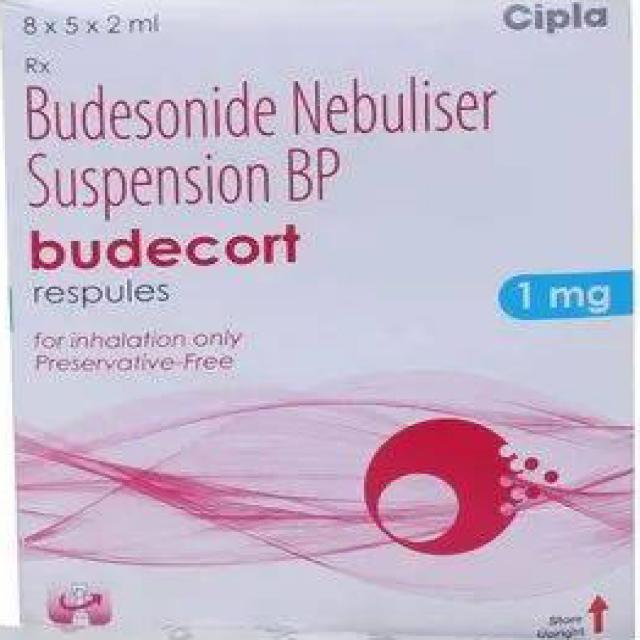


MODEL ANALYSIS
----------------------------------------
Prediction count: 1

Prediction 1:
Raw prediction: score=0.9241480231285095 label_name='Medicine' label_index=1 id='adbb3f5c-2911-4acd-8b0c-e7eba3e9e6d6' bboxes=(9, 50, 515, 209)
Detected label: Medicine
Class index: 1
Confidence: 0.9241480231285095


In [20]:
import numpy as np
from IPython.display import display, Markdown

def medicine_bottle_assistant(file_paths):

    print("Medicine Bottle Cognitive Assistant")

    for i, file_path in enumerate(file_paths, start=1):

        image = Image.open(file_path).convert("RGB")

        print("\n" + "=" * 60)
        print(f"MEDICINE IMAGE {i}: {os.path.basename(file_path)}")
        print("=" * 60)

        display(image)

        image_array = np.array(image)

        predictions = predictor.predict(image_array)

        print("\nMODEL ANALYSIS")
        print("-" * 40)

        print("Prediction count:", len(predictions))

        if not predictions:
            print("No predictions returned by the model.")
            continue

        for j, prediction in enumerate(predictions, start=1):

            print(f"\nPrediction {j}:")

            print("Raw prediction:", prediction)

            print("Detected label:",
                  getattr(prediction, "label_name", "Not available"))

            print("Class index:",
                  getattr(prediction, "label_index", "Not available"))

            print("Confidence:",
                  getattr(prediction, "score", "Not available"))

medicine_bottle_assistant(file_paths)

In [21]:
import os
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from tkinter import Tk, filedialog
from landingai.predict import Predictor

from getpass import getpass

In [27]:
endpoint_id = "56ca3275-73b7-4195-85c6-4e6508e18b08"

emotion_predictor = Predictor(
    endpoint_id,
    api_key=EMOTION_API_KEY
)

print("Emotion Detection predictor initialized successfully.")

Emotion Detection predictor initialized successfully.


In [29]:
root = Tk()
root.withdraw()
root.attributes("-topmost", True)

emotion_file_paths = filedialog.askopenfilenames(
    title="Select Facial Expression Images",
    filetypes=[
        ("Image files", "*.jpg *.jpeg *.png *.bmp")
    ]
)

root.destroy()

print("Total images selected:", len(emotion_file_paths))

Total images selected: 2


Emotion-Aware Facial Expression Detection Assistant

IMAGE 1: angry_test_03.jpg


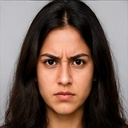


MODEL ANALYSIS
----------------------------------------
Prediction count: 1

Prediction 1:
Raw prediction: score=0.35108256340026855 label_name='neutral' label_index=4 id='48a9c6f6-1194-4403-a017-0c2b6369fef8' bboxes=(0, 3, 125, 126)
Detected emotion: neutral
Class index: 4
Confidence: 0.35108256340026855

IMAGE 2: happy_test_01.jpg


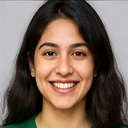


MODEL ANALYSIS
----------------------------------------
Prediction count: 1

Prediction 1:
Raw prediction: score=0.357928991317749 label_name='neutral' label_index=4 id='3f8da305-8671-4202-853d-04b54a98d8f1' bboxes=(2, 1, 126, 124)
Detected emotion: neutral
Class index: 4
Confidence: 0.357928991317749


In [30]:
def emotion_detection_assistant(file_paths):

    print("Emotion-Aware Facial Expression Detection Assistant")

    for i, file_path in enumerate(file_paths, start=1):

        image = Image.open(file_path).convert("RGB")

        print("\n" + "=" * 60)
        print(f"IMAGE {i}: {os.path.basename(file_path)}")
        print("=" * 60)

        display(image)

        predictions = emotion_predictor.predict(np.array(image))

        print("\nMODEL ANALYSIS")
        print("-" * 40)

        print("Prediction count:", len(predictions))

        if not predictions:
            print("No predictions returned by the model.")
            continue

        for j, prediction in enumerate(predictions, start=1):

            print(f"\nPrediction {j}:")
            print("Raw prediction:", prediction)

            print("Detected emotion:",
                  getattr(prediction, "label_name", "Not available"))

            print("Class index:",
                  getattr(prediction, "label_index", "Not available"))

            print("Confidence:",
                  getattr(prediction, "score", "Not available"))


emotion_detection_assistant(emotion_file_paths)